In [336]:
require(data.table)
require(ggplot2)
require(cowplot)
require(ggpubr)
require(pbapply)
require(viridis)
require(rtracklayer)
require(BSgenome.Hsapiens.UCSC.hg38)

# Generating masking file for hg38

In [337]:
md = import.bed("https://bismap.hoffmanlab.org/raw/hg38/k50.umap.bed.gz")
chromosomes = paste0("chr", c(1:22, "X"))
md = keepSeqlevels(md, chromosomes, pruning.mode = "coarse")
seqinfo(md) = seqinfo(BSgenome.Hsapiens.UCSC.hg38)
md = keepSeqlevels(md, chromosomes, pruning.mode = "coarse")

head(md)

UCSC track 'Umap S50'
UCSCData object with 6 ranges and 2 metadata columns:
      seqnames      ranges strand |        name     score
         <Rle>   <IRanges>  <Rle> | <character> <numeric>
  [1]     chr1 10070-10488      * |         k50         1
  [2]     chr1 10561-10671      * |         k50         1
  [3]     chr1 10767-10863      * |         k50         1
  [4]     chr1 13066-13120      * |         k50         1
  [5]     chr1 13277-13375      * |         k50         1
  [6]     chr1 13930-14028      * |         k50         1
  -------
  seqinfo: 23 sequences from hg38 genome

In [338]:
bins = import.bed("./hg38_bins_1e+06_1e+05.bed")
bins = keepSeqlevels(bins, chromosomes, pruning.mode = "coarse")
seqinfo(bins) = seqinfo(BSgenome.Hsapiens.UCSC.hg38)
bins = keepSeqlevels(bins, chromosomes, pruning.mode = "coarse")
tmp = coverage(md)
b = keepSeqlevels(bins, intersect(seqlevels(bins), seqlevels(tmp)),
                      pruning.mode = "coarse")

head(b)

GRanges object with 6 ranges and 1 metadata column:
      seqnames         ranges strand |        name
         <Rle>      <IRanges>  <Rle> | <character>
  [1]     chr1      1-1000000      * |      chr1_1
  [2]     chr1 100001-1100000      * |      chr1_2
  [3]     chr1 200001-1200000      * |      chr1_3
  [4]     chr1 300001-1300000      * |      chr1_4
  [5]     chr1 400001-1400000      * |      chr1_5
  [6]     chr1 500001-1500000      * |      chr1_6
  -------
  seqinfo: 23 sequences from hg38 genome

In [339]:
    sco = sapply(seq(1, length(b), 1e3),
        function(bi) {
            bi = as.numeric(as.character(bi))
            sub = b[bi:min(bi + 1e3 - 1, length(b))]
            mean(tmp[sub], na.rm = T)
        }
    )

In [340]:
bd = as.data.table(bins)[, list(chrom = seqnames, start, end)]
bd$mappability = unlist(sco)

In [341]:
bd_1m = copy(bd)

In [342]:
head(bd_1m)

chrom,start,end,mappability
<fct>,<int>,<int>,<dbl>
chr1,1,1000000,0.279537
chr1,100001,1100000,0.355516
chr1,200001,1200000,0.438121
chr1,300001,1300000,0.524933
chr1,400001,1400000,0.622362
chr1,500001,1500000,0.712322


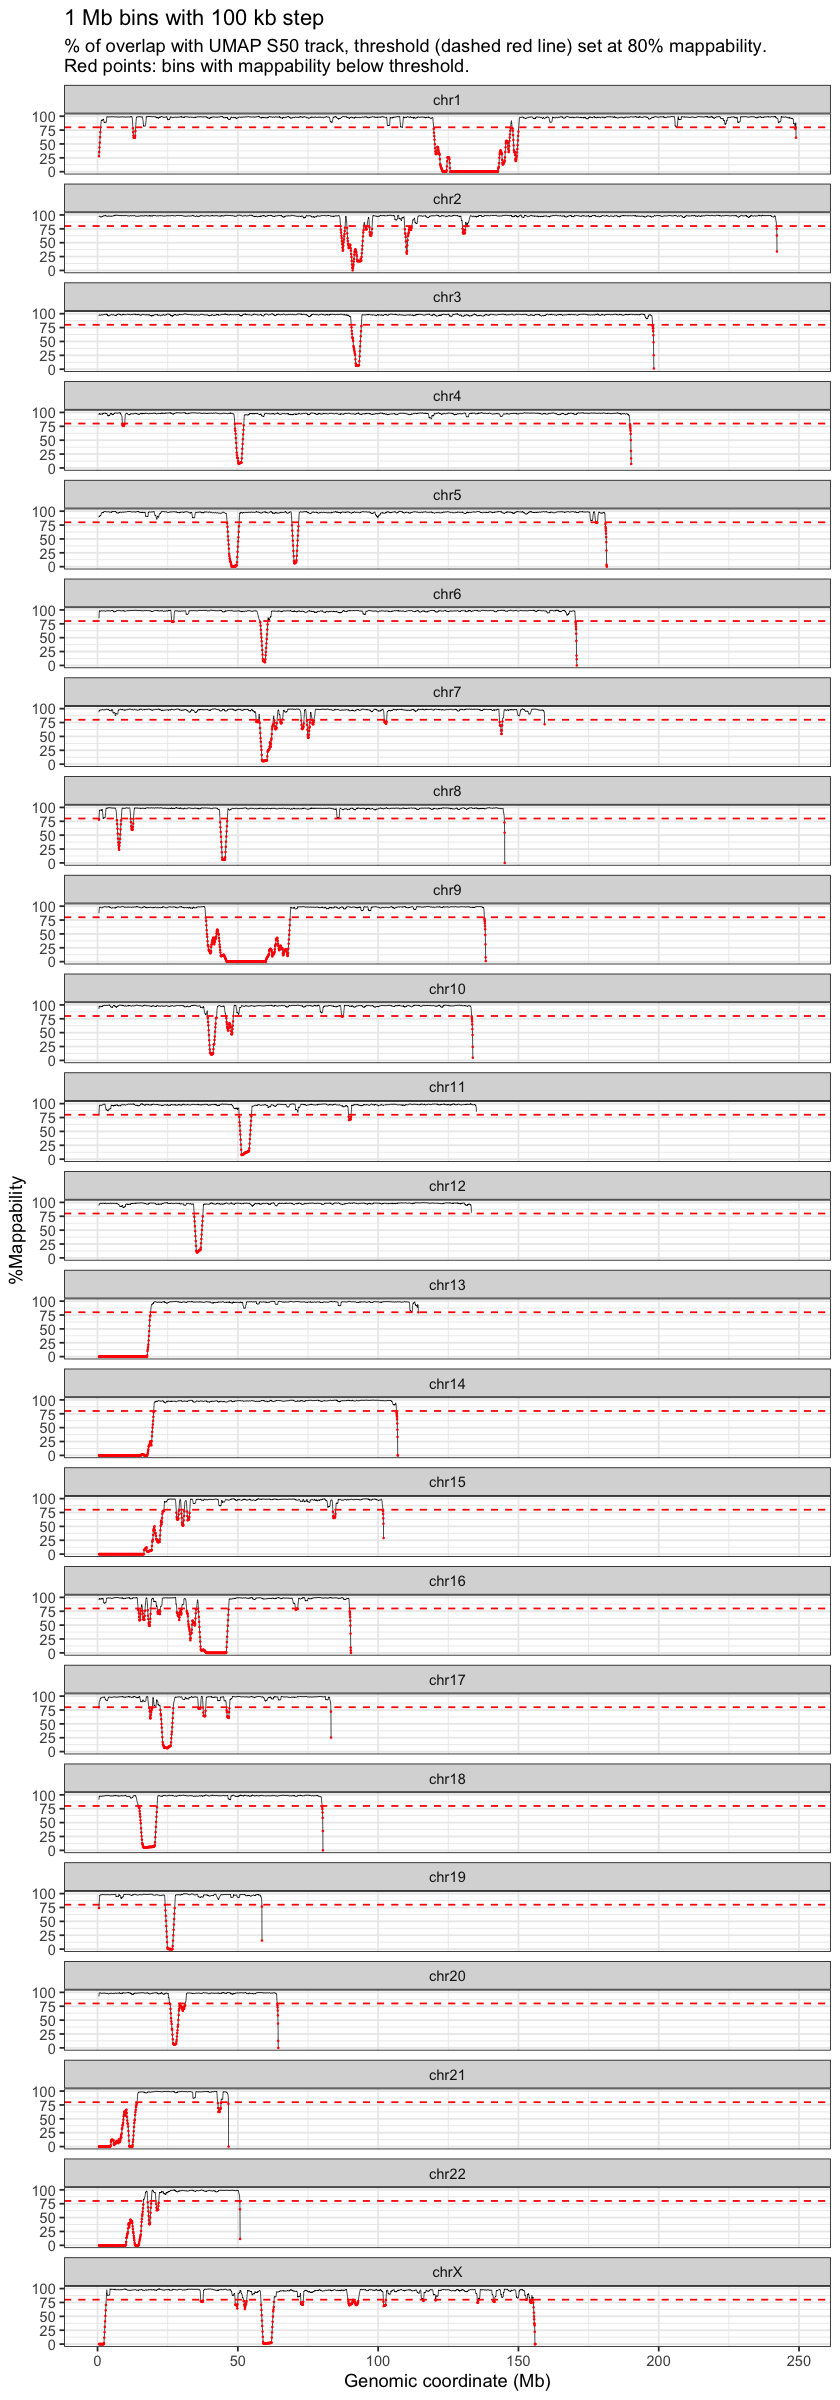

In [343]:
options(repr.plot.width=7, repr.plot.height=20)

threshold<-0.8
klen<-50

p = ggplot(bd_1m, aes((start + end) / 2e6, mappability * 100)
        ) + geom_line(size = .2
        ) + geom_point(data = bd_1m[mappability < threshold],
            color = "red", size = .05
        ) + facet_wrap(~chrom, ncol = 1
        ) + labs(x = "Genomic coordinate (Mb)", y = "%Mappability",
            title = "1 Mb bins with 100 kb step",
            subtitle = paste0(
                sprintf("%% of overlap with UMAP S%d track, ", klen),
                sprintf(
                    "threshold (dashed red line) set at %d%% mappability.\n",
                    threshold * 100),
                "Red points: bins with mappability below threshold.")
        ) + scale_color_manual(values = c("black", "red")
        ) + geom_hline(yintercept = threshold * 100,
            color = "red", linetype = "dashed"
        ) + theme_bw(
        )
p

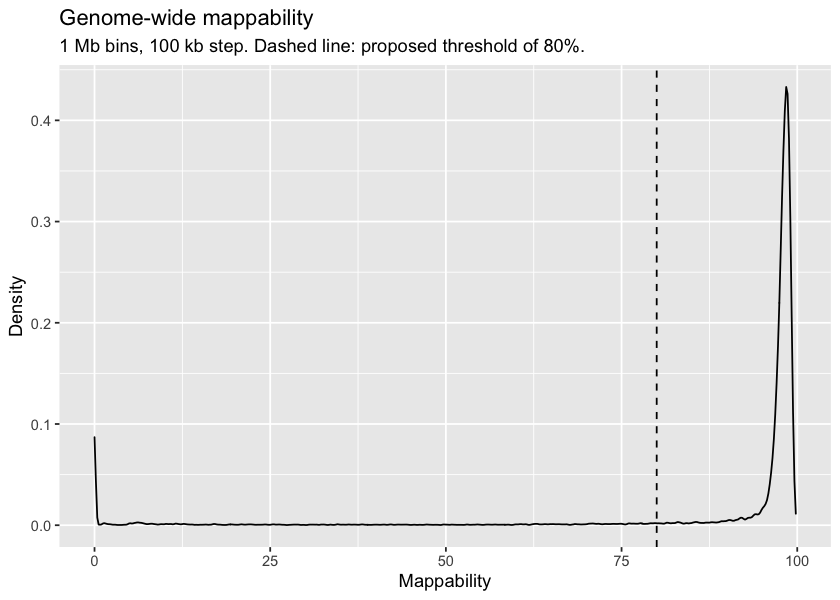

In [344]:
options(repr.plot.width=7, repr.plot.height=5)
p = ggplot(bd_1m, aes(mappability * 100)
        ) + geom_density(
        ) + geom_vline(xintercept = threshold * 100, linetype = "dashed"
        ) + labs(x = "Mappability", y = "Density",
            title = "Genome-wide mappability",
            subtitle = paste0("1 Mb bins, 100 kb step. ",
                sprintf("Dashed line: proposed threshold of %d%%.",
                    threshold * 100))
        )
p

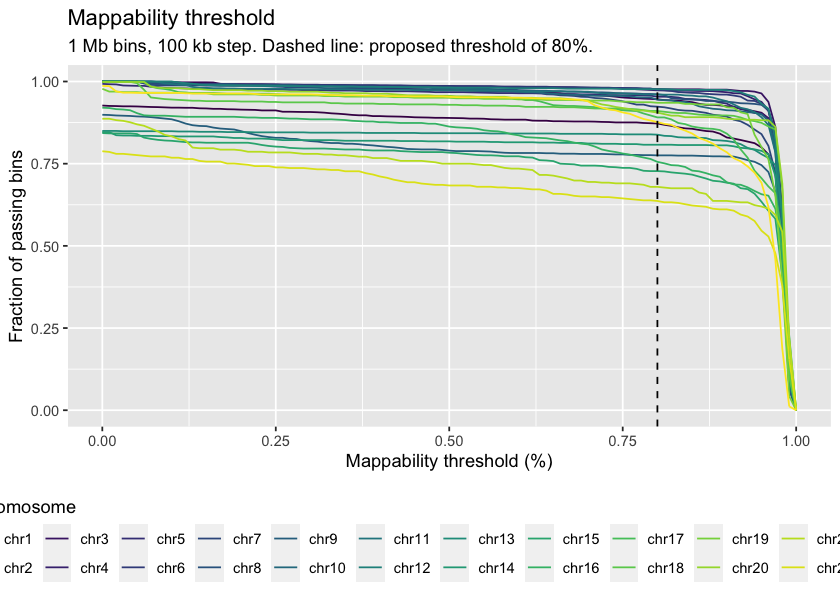

In [345]:
passing = rbindlist(lapply(seq(0, 1, by = .01), function(thr) {
        bd_1m[, list(pass = sum(get("mappability") > thr), N = .N, thr),
              by = chrom]
    }))
passing[, c("f") := list(get("pass") / get("N"))]
p = ggplot(passing, aes(x = thr, y = f, color = chrom)
        ) + geom_line(
        ) + geom_vline(xintercept = threshold, linetype = "dashed"
        ) + labs(x = "Mappability threshold (%)",
            y = "Fraction of passing bins",
            color = "Chromosome", title = "Mappability threshold",
            subtitle = paste0("1 Mb bins, 100 kb step. ",
                sprintf("Dashed line: proposed threshold of %d%%.",
                    threshold * 100))
        ) + theme(legend.position = "bottom"
        ) + guides(color = guide_legend(nrow = 2, title.position = "top")
        ) + scale_color_viridis(discrete = T)
p

Warning message:
“`guides(<scale> = FALSE)` is deprecated. Please use `guides(<scale> = "none")` instead.”


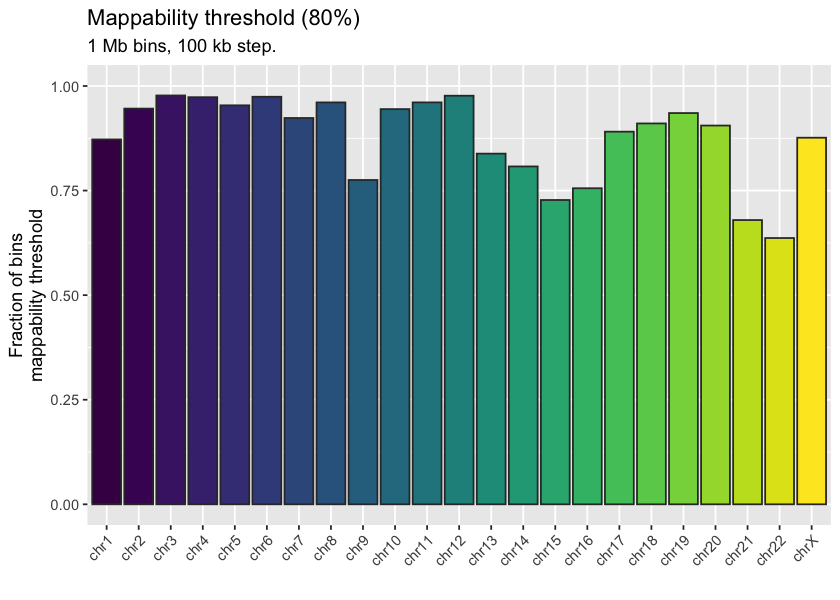

In [346]:
p = ggplot(passing[thr == threshold], aes(x = chrom, y = f, fill = chrom)
        ) + geom_col(color = "#323232"
        ) + scale_fill_viridis(discrete = T
        ) + guides(fill = F
        ) + theme(axis.text.x = element_text(angle = 45, hjust = 1)
        ) + coord_cartesian(ylim = c(0, 1)
        ) + labs(x = "", y = "Fraction of bins\nmappability threshold",
            title = sprintf("Mappability threshold (%d%%)", threshold * 100),
            subtitle = "1 Mb bins, 100 kb step."
        )
p

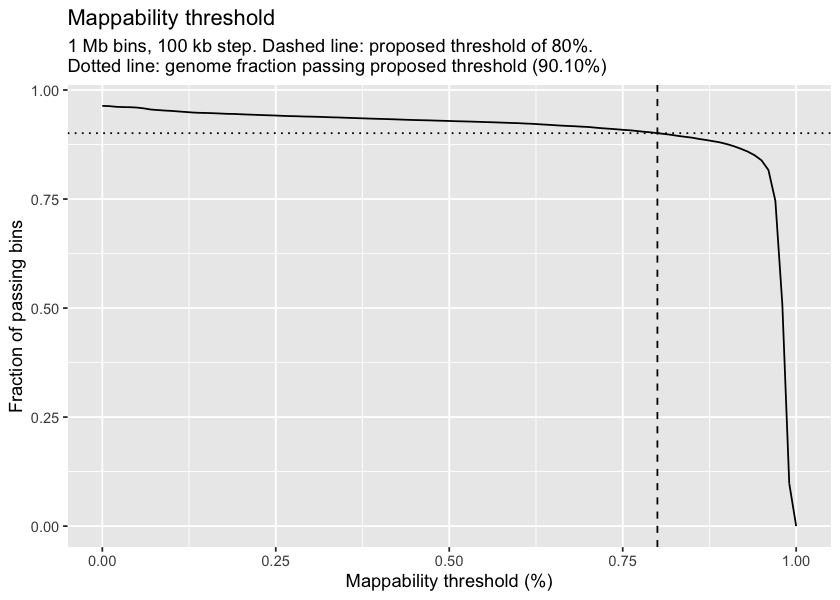

In [347]:
passing = rbindlist(lapply(seq(0, 1, by = .01), function(thr) {
        bd_1m[, list(pass = sum(get("mappability") > thr), N = .N, thr)]
    }))
passing[, c("f") := list(get("pass") / get("N"))]
passing_fraction = 1 - bd_1m[, sum(get("mappability") < threshold) / .N]
p = ggplot(passing, aes(x = thr, y = f)
        ) + geom_line(
        ) + geom_vline(xintercept = threshold, linetype = "dashed"
        ) + geom_hline(yintercept = passing_fraction,
            linetype = "dotted"
        ) + labs(x = "Mappability threshold (%)",
            y = "Fraction of passing bins",
            title = "Mappability threshold",
            subtitle = paste0("1 Mb bins, 100 kb step. ",
                sprintf("Dashed line: proposed threshold of %d%%.\n",
                    threshold * 100),
                "Dotted line: genome fraction passing proposed threshold ",
                sprintf("(%.2f%%)", passing_fraction * 100))
        ) + theme(legend.position = "bottom"
        )
p

In [348]:
write.table(bd_1m[mappability < threshold, .(chrom, start, end)], "hg38_low_mappability.UMAP_S50.bins_1e+06_1e+05.tsv",sep="\t",
            quote = F, row.names = FALSE, col.names = FALSE)

# Generating masking file for mm10

In [349]:
require(BSgenome.Mmusculus.UCSC.mm10)

In [350]:
md = import.bed("https://bismap.hoffmanlab.org/raw/mm10/k50.umap.bed.gz")
chromosomes = paste0("chr", c(1:19, "X"))
md = keepSeqlevels(md, chromosomes, pruning.mode = "coarse")
seqinfo(md) = seqinfo(BSgenome.Mmusculus.UCSC.mm10)
md = keepSeqlevels(md, chromosomes, pruning.mode = "coarse")

head(md)

UCSC track 'Umap S50'
UCSCData object with 6 ranges and 2 metadata columns:
      seqnames          ranges strand |        name     score
         <Rle>       <IRanges>  <Rle> | <character> <numeric>
  [1]     chr1 3000000-3001394      * |         k50         1
  [2]     chr1 3001440-3001939      * |         k50         1
  [3]     chr1 3001941-3002154      * |         k50         1
  [4]     chr1 3003118-3014841      * |         k50         1
  [5]     chr1 3014863-3014931      * |         k50         1
  [6]     chr1 3014971-3015171      * |         k50         1
  -------
  seqinfo: 20 sequences from mm10 genome

In [351]:
bins = import.bed("./mm10_bins_1e+06_1e+05.bed")
bins = keepSeqlevels(bins, chromosomes, pruning.mode = "coarse")
seqinfo(bins) = seqinfo(BSgenome.Mmusculus.UCSC.mm10)
bins = keepSeqlevels(bins, chromosomes, pruning.mode = "coarse")
tmp = coverage(md)
b = keepSeqlevels(bins, intersect(seqlevels(bins), seqlevels(tmp)),
                      pruning.mode = "coarse")

head(b)

GRanges object with 6 ranges and 1 metadata column:
      seqnames         ranges strand |        name
         <Rle>      <IRanges>  <Rle> | <character>
  [1]     chr1      1-1000000      * |      chr1_1
  [2]     chr1 100001-1100000      * |      chr1_2
  [3]     chr1 200001-1200000      * |      chr1_3
  [4]     chr1 300001-1300000      * |      chr1_4
  [5]     chr1 400001-1400000      * |      chr1_5
  [6]     chr1 500001-1500000      * |      chr1_6
  -------
  seqinfo: 20 sequences from mm10 genome

In [352]:
    sco = sapply(seq(1, length(b), 1e3),
        function(bi) {
            bi = as.numeric(as.character(bi))
            sub = b[bi:min(bi + 1e3 - 1, length(b))]
            mean(tmp[sub], na.rm = T)
        }
    )

In [353]:
bd = as.data.table(bins)[, list(chrom = seqnames, start, end)]
bd$mappability = unlist(sco)

In [354]:
bd_1m = copy(bd)

In [355]:
head(bd_1m)

chrom,start,end,mappability
<fct>,<int>,<int>,<dbl>
chr1,1,1000000,0
chr1,100001,1100000,0
chr1,200001,1200000,0
chr1,300001,1300000,0
chr1,400001,1400000,0
chr1,500001,1500000,0


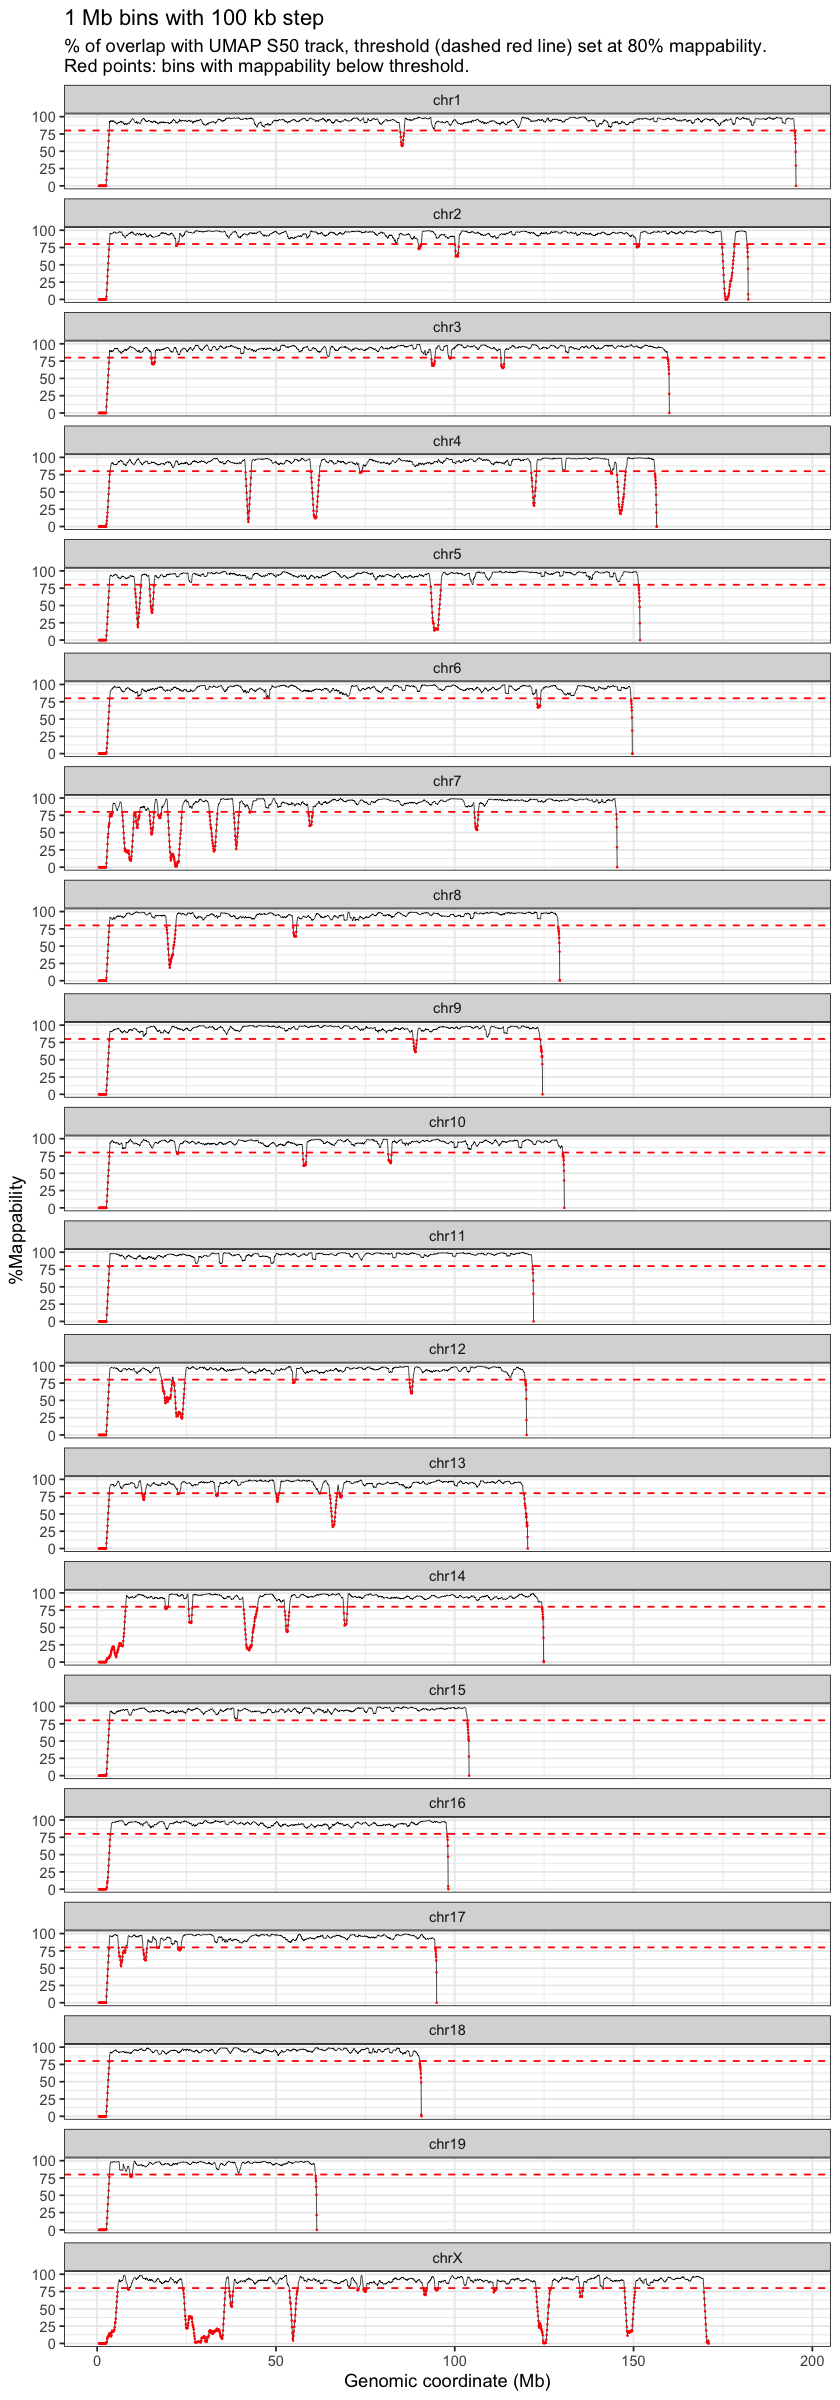

In [356]:
options(repr.plot.width=7, repr.plot.height=20)

threshold<-0.8
klen<-50

p = ggplot(bd_1m, aes((start + end) / 2e6, mappability * 100)
        ) + geom_line(size = .2
        ) + geom_point(data = bd_1m[mappability < threshold],
            color = "red", size = .05
        ) + facet_wrap(~chrom, ncol = 1
        ) + labs(x = "Genomic coordinate (Mb)", y = "%Mappability",
            title = "1 Mb bins with 100 kb step",
            subtitle = paste0(
                sprintf("%% of overlap with UMAP S%d track, ", klen),
                sprintf(
                    "threshold (dashed red line) set at %d%% mappability.\n",
                    threshold * 100),
                "Red points: bins with mappability below threshold.")
        ) + scale_color_manual(values = c("black", "red")
        ) + geom_hline(yintercept = threshold * 100,
            color = "red", linetype = "dashed"
        ) + theme_bw(
        )
p

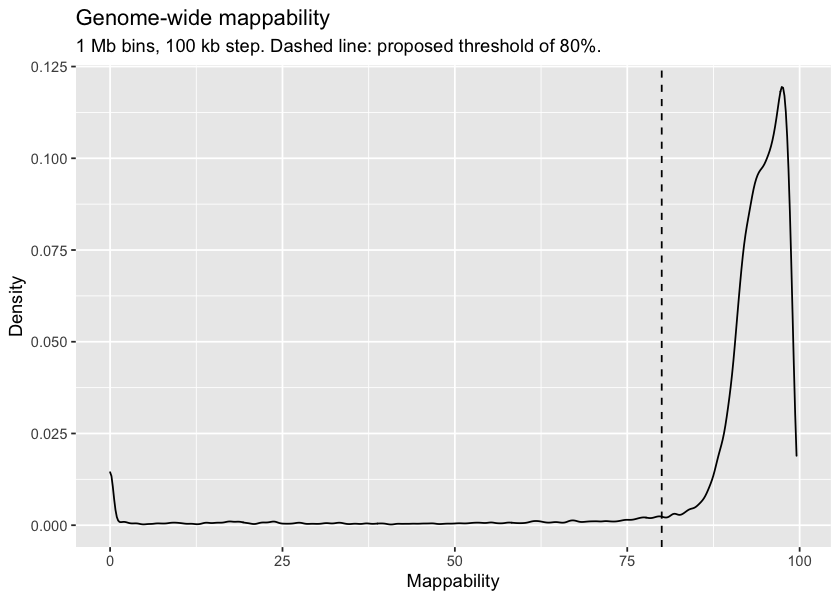

In [357]:
options(repr.plot.width=7, repr.plot.height=5)
p = ggplot(bd_1m, aes(mappability * 100)
        ) + geom_density(
        ) + geom_vline(xintercept = threshold * 100, linetype = "dashed"
        ) + labs(x = "Mappability", y = "Density",
            title = "Genome-wide mappability",
            subtitle = paste0("1 Mb bins, 100 kb step. ",
                sprintf("Dashed line: proposed threshold of %d%%.",
                    threshold * 100))
        )
p

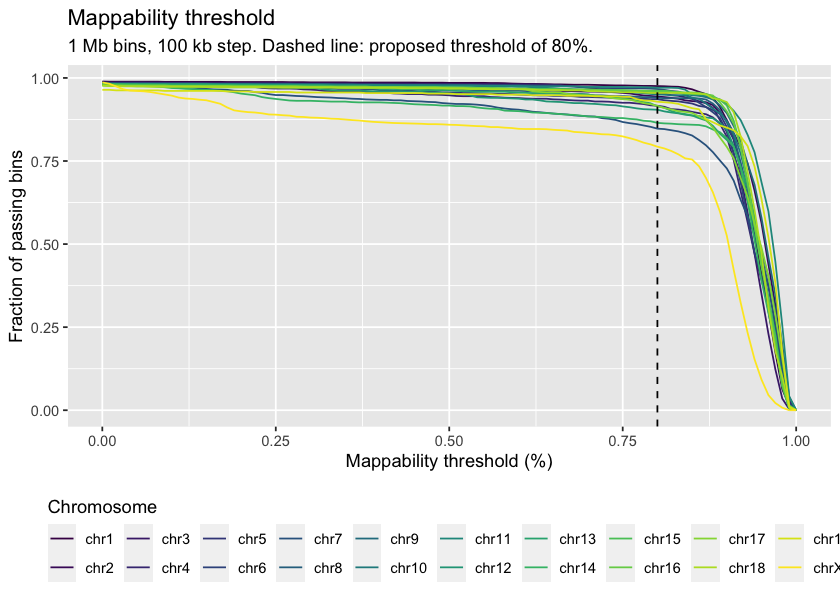

In [358]:
passing = rbindlist(lapply(seq(0, 1, by = .01), function(thr) {
        bd_1m[, list(pass = sum(get("mappability") > thr), N = .N, thr),
              by = chrom]
    }))
passing[, c("f") := list(get("pass") / get("N"))]
p = ggplot(passing, aes(x = thr, y = f, color = chrom)
        ) + geom_line(
        ) + geom_vline(xintercept = threshold, linetype = "dashed"
        ) + labs(x = "Mappability threshold (%)",
            y = "Fraction of passing bins",
            color = "Chromosome", title = "Mappability threshold",
            subtitle = paste0("1 Mb bins, 100 kb step. ",
                sprintf("Dashed line: proposed threshold of %d%%.",
                    threshold * 100))
        ) + theme(legend.position = "bottom"
        ) + guides(color = guide_legend(nrow = 2, title.position = "top")
        ) + scale_color_viridis(discrete = T)
p

Warning message:
“`guides(<scale> = FALSE)` is deprecated. Please use `guides(<scale> = "none")` instead.”


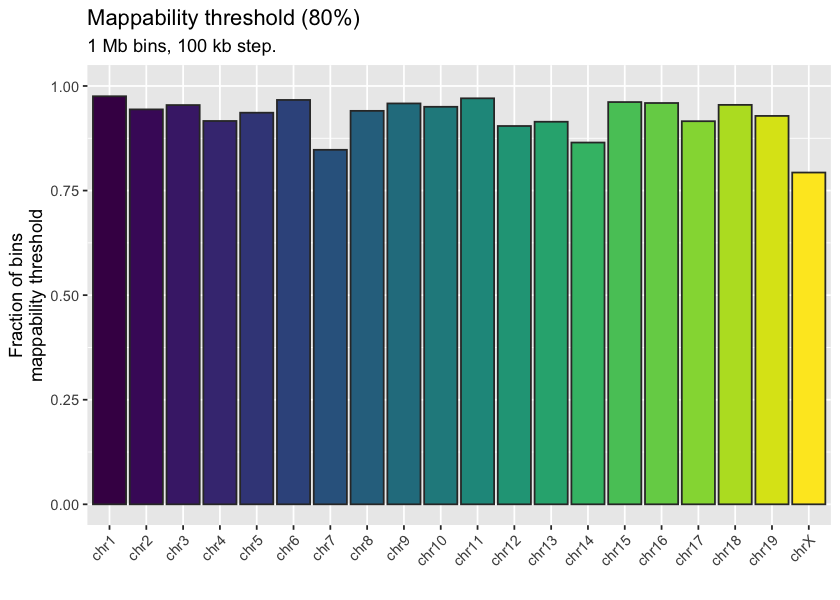

In [359]:
p = ggplot(passing[thr == threshold], aes(x = chrom, y = f, fill = chrom)
        ) + geom_col(color = "#323232"
        ) + scale_fill_viridis(discrete = T
        ) + guides(fill = F
        ) + theme(axis.text.x = element_text(angle = 45, hjust = 1)
        ) + coord_cartesian(ylim = c(0, 1)
        ) + labs(x = "", y = "Fraction of bins\nmappability threshold",
            title = sprintf("Mappability threshold (%d%%)", threshold * 100),
            subtitle = "1 Mb bins, 100 kb step."
        )
p

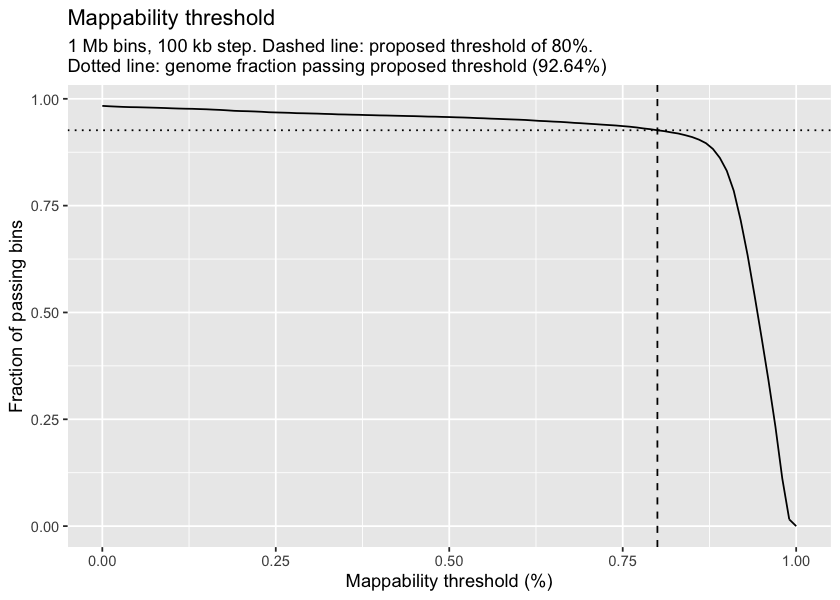

In [360]:
passing = rbindlist(lapply(seq(0, 1, by = .01), function(thr) {
        bd_1m[, list(pass = sum(get("mappability") > thr), N = .N, thr)]
    }))
passing[, c("f") := list(get("pass") / get("N"))]
passing_fraction = 1 - bd_1m[, sum(get("mappability") < threshold) / .N]
p = ggplot(passing, aes(x = thr, y = f)
        ) + geom_line(
        ) + geom_vline(xintercept = threshold, linetype = "dashed"
        ) + geom_hline(yintercept = passing_fraction,
            linetype = "dotted"
        ) + labs(x = "Mappability threshold (%)",
            y = "Fraction of passing bins",
            title = "Mappability threshold",
            subtitle = paste0("1 Mb bins, 100 kb step. ",
                sprintf("Dashed line: proposed threshold of %d%%.\n",
                    threshold * 100),
                "Dotted line: genome fraction passing proposed threshold ",
                sprintf("(%.2f%%)", passing_fraction * 100))
        ) + theme(legend.position = "bottom"
        )
p

In [361]:
write.table(bd_1m[mappability < threshold, .(chrom, start, end)], "mm10_low_mappability.UMAP_S50.bins_1e+06_1e+05.tsv",sep="\t",
            quote = F, row.names = FALSE, col.names = FALSE)

# Generating masking file for hg19

In [362]:
require(BSgenome.Hsapiens.UCSC.hg19)

In [363]:
md = import.bed("https://bismap.hoffmanlab.org/raw/hg19/k50.umap.bed.gz")
chromosomes = paste0("chr", c(1:22, "X"))
md = keepSeqlevels(md, chromosomes, pruning.mode = "coarse")
seqinfo(md) = seqinfo(BSgenome.Hsapiens.UCSC.hg19)
md = keepSeqlevels(md, chromosomes, pruning.mode = "coarse")

head(md)

UCSC track 'Umap S50'
UCSCData object with 6 ranges and 2 metadata columns:
      seqnames      ranges strand |        name     score
         <Rle>   <IRanges>  <Rle> | <character> <numeric>
  [1]     chr1 10070-10671      * |         k50         1
  [2]     chr1 10767-10863      * |         k50         1
  [3]     chr1 13029-13120      * |         k50         1
  [4]     chr1 13277-13375      * |         k50         1
  [5]     chr1 13458-13521      * |         k50         1
  [6]     chr1 13930-14028      * |         k50         1
  -------
  seqinfo: 23 sequences from hg19 genome

In [364]:
bins = import.bed("./hg19_bins_1e+06_1e+05.bed")
bins = keepSeqlevels(bins, chromosomes, pruning.mode = "coarse")
seqinfo(bins) = seqinfo(BSgenome.Hsapiens.UCSC.hg19)
bins = keepSeqlevels(bins, chromosomes, pruning.mode = "coarse")
tmp = coverage(md)
b = keepSeqlevels(bins, intersect(seqlevels(bins), seqlevels(tmp)),
                      pruning.mode = "coarse")

head(b)

GRanges object with 6 ranges and 1 metadata column:
      seqnames         ranges strand |        name
         <Rle>      <IRanges>  <Rle> | <character>
  [1]     chr1      1-1000000      * |      chr1_1
  [2]     chr1 100001-1100000      * |      chr1_2
  [3]     chr1 200001-1200000      * |      chr1_3
  [4]     chr1 300001-1300000      * |      chr1_4
  [5]     chr1 400001-1400000      * |      chr1_5
  [6]     chr1 500001-1500000      * |      chr1_6
  -------
  seqinfo: 23 sequences from hg19 genome

In [365]:
    sco = sapply(seq(1, length(b), 1e3),
        function(bi) {
            bi = as.numeric(as.character(bi))
            sub = b[bi:min(bi + 1e3 - 1, length(b))]
            mean(tmp[sub], na.rm = T)
        }
    )

In [366]:
bd = as.data.table(bins)[, list(chrom = seqnames, start, end)]
bd$mappability = unlist(sco)

In [367]:
bd_1m = copy(bd)

In [368]:
head(bd_1m)

chrom,start,end,mappability
<fct>,<int>,<int>,<dbl>
chr1,1,1000000,0.334338
chr1,100001,1100000,0.408653
chr1,200001,1200000,0.495645
chr1,300001,1300000,0.583658
chr1,400001,1400000,0.678339
chr1,500001,1500000,0.767096


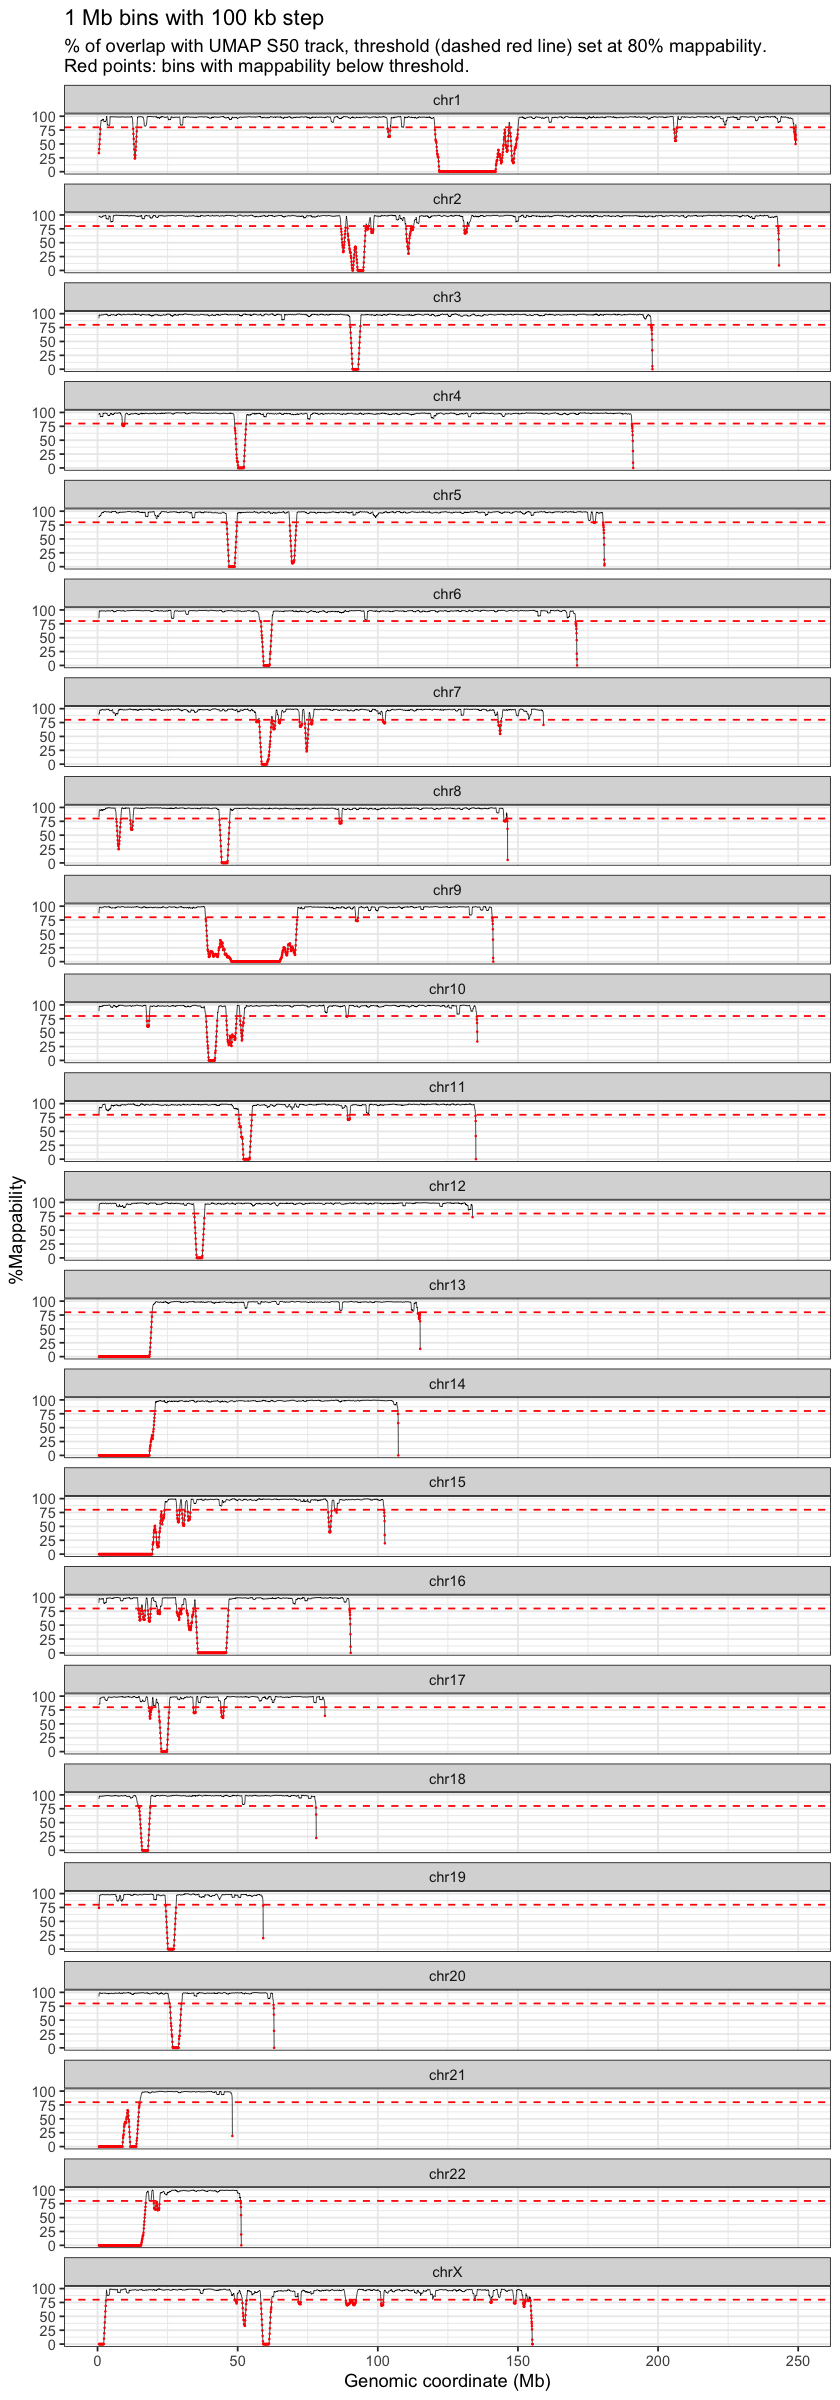

In [369]:
options(repr.plot.width=7, repr.plot.height=20)

threshold<-0.8
klen<-50

p = ggplot(bd_1m, aes((start + end) / 2e6, mappability * 100)
        ) + geom_line(size = .2
        ) + geom_point(data = bd_1m[mappability < threshold],
            color = "red", size = .05
        ) + facet_wrap(~chrom, ncol = 1
        ) + labs(x = "Genomic coordinate (Mb)", y = "%Mappability",
            title = "1 Mb bins with 100 kb step",
            subtitle = paste0(
                sprintf("%% of overlap with UMAP S%d track, ", klen),
                sprintf(
                    "threshold (dashed red line) set at %d%% mappability.\n",
                    threshold * 100),
                "Red points: bins with mappability below threshold.")
        ) + scale_color_manual(values = c("black", "red")
        ) + geom_hline(yintercept = threshold * 100,
            color = "red", linetype = "dashed"
        ) + theme_bw(
        )
p

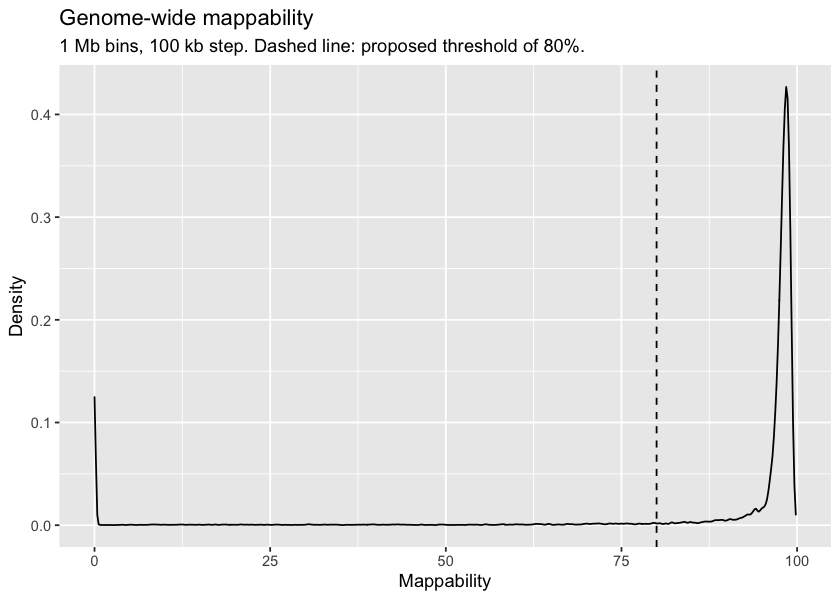

In [370]:
options(repr.plot.width=7, repr.plot.height=5)
p = ggplot(bd_1m, aes(mappability * 100)
        ) + geom_density(
        ) + geom_vline(xintercept = threshold * 100, linetype = "dashed"
        ) + labs(x = "Mappability", y = "Density",
            title = "Genome-wide mappability",
            subtitle = paste0("1 Mb bins, 100 kb step. ",
                sprintf("Dashed line: proposed threshold of %d%%.",
                    threshold * 100))
        )
p

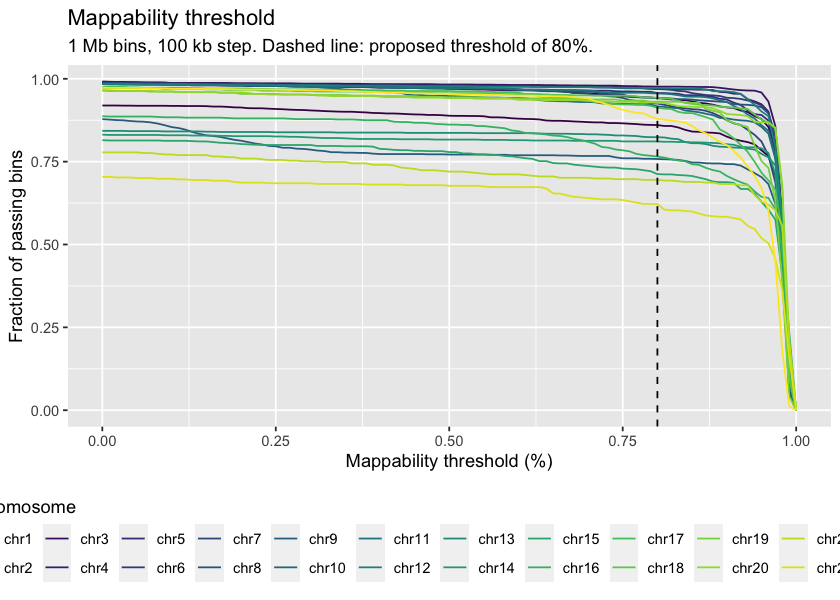

In [371]:
passing = rbindlist(lapply(seq(0, 1, by = .01), function(thr) {
        bd_1m[, list(pass = sum(get("mappability") > thr), N = .N, thr),
              by = chrom]
    }))
passing[, c("f") := list(get("pass") / get("N"))]
p = ggplot(passing, aes(x = thr, y = f, color = chrom)
        ) + geom_line(
        ) + geom_vline(xintercept = threshold, linetype = "dashed"
        ) + labs(x = "Mappability threshold (%)",
            y = "Fraction of passing bins",
            color = "Chromosome", title = "Mappability threshold",
            subtitle = paste0("1 Mb bins, 100 kb step. ",
                sprintf("Dashed line: proposed threshold of %d%%.",
                    threshold * 100))
        ) + theme(legend.position = "bottom"
        ) + guides(color = guide_legend(nrow = 2, title.position = "top")
        ) + scale_color_viridis(discrete = T)
p

Warning message:
“`guides(<scale> = FALSE)` is deprecated. Please use `guides(<scale> = "none")` instead.”


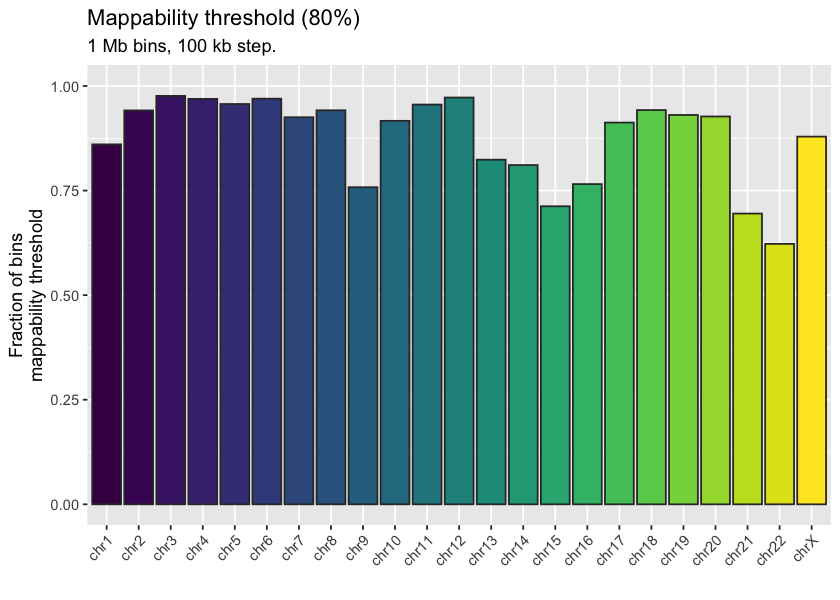

In [372]:
p = ggplot(passing[thr == threshold], aes(x = chrom, y = f, fill = chrom)
        ) + geom_col(color = "#323232"
        ) + scale_fill_viridis(discrete = T
        ) + guides(fill = F
        ) + theme(axis.text.x = element_text(angle = 45, hjust = 1)
        ) + coord_cartesian(ylim = c(0, 1)
        ) + labs(x = "", y = "Fraction of bins\nmappability threshold",
            title = sprintf("Mappability threshold (%d%%)", threshold * 100),
            subtitle = "1 Mb bins, 100 kb step."
        )
p

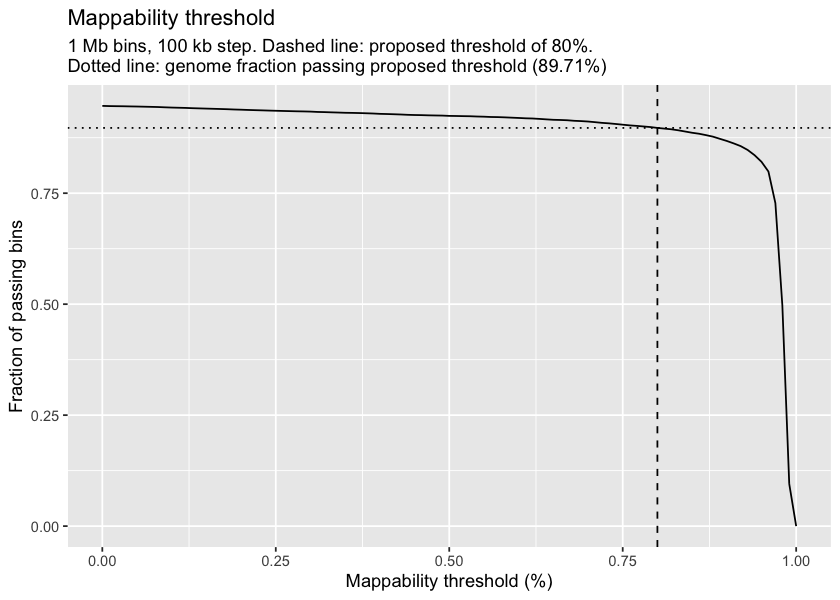

In [373]:
passing = rbindlist(lapply(seq(0, 1, by = .01), function(thr) {
        bd_1m[, list(pass = sum(get("mappability") > thr), N = .N, thr)]
    }))
passing[, c("f") := list(get("pass") / get("N"))]
passing_fraction = 1 - bd_1m[, sum(get("mappability") < threshold) / .N]
p = ggplot(passing, aes(x = thr, y = f)
        ) + geom_line(
        ) + geom_vline(xintercept = threshold, linetype = "dashed"
        ) + geom_hline(yintercept = passing_fraction,
            linetype = "dotted"
        ) + labs(x = "Mappability threshold (%)",
            y = "Fraction of passing bins",
            title = "Mappability threshold",
            subtitle = paste0("1 Mb bins, 100 kb step. ",
                sprintf("Dashed line: proposed threshold of %d%%.\n",
                    threshold * 100),
                "Dotted line: genome fraction passing proposed threshold ",
                sprintf("(%.2f%%)", passing_fraction * 100))
        ) + theme(legend.position = "bottom"
        )
p

In [374]:
write.table(bd_1m[mappability < threshold, .(chrom, start, end)], "hg19_low_mappability.UMAP_S50.bins_1e+06_1e+05.tsv",sep="\t",
            quote = F, row.names = FALSE, col.names = FALSE)

# Generating masking file for mm9

In [375]:
require(BSgenome.Mmusculus.UCSC.mm9)

In [376]:
md = import.bed("https://bismap.hoffmanlab.org/raw/mm9/k50.umap.bed.gz")
chromosomes = paste0("chr", c(1:19, "X"))
md = keepSeqlevels(md, chromosomes, pruning.mode = "coarse")
seqinfo(md) = seqinfo(BSgenome.Mmusculus.UCSC.mm9)
md = keepSeqlevels(md, chromosomes, pruning.mode = "coarse")

head(md)

UCSC track 'Umap S50'
UCSCData object with 6 ranges and 2 metadata columns:
      seqnames          ranges strand |        name     score
         <Rle>       <IRanges>  <Rle> | <character> <numeric>
  [1]     chr1 3000000-3004922      * |         k50         1
  [2]     chr1 3004944-3005012      * |         k50         1
  [3]     chr1 3005052-3005252      * |         k50         1
  [4]     chr1 3005356-3005524      * |         k50         1
  [5]     chr1 3005537-3005664      * |         k50         1
  [6]     chr1 3005745-3005869      * |         k50         1
  -------
  seqinfo: 20 sequences from mm9 genome

In [377]:
bins = import.bed("./mm9_bins_1e+06_1e+05.bed")
bins = keepSeqlevels(bins, chromosomes, pruning.mode = "coarse")
seqinfo(bins) = seqinfo(BSgenome.Mmusculus.UCSC.mm9)
bins = keepSeqlevels(bins, chromosomes, pruning.mode = "coarse")
tmp = coverage(md)
b = keepSeqlevels(bins, intersect(seqlevels(bins), seqlevels(tmp)),
                      pruning.mode = "coarse")

head(b)

GRanges object with 6 ranges and 1 metadata column:
      seqnames         ranges strand |        name
         <Rle>      <IRanges>  <Rle> | <character>
  [1]     chr1      1-1000000      * |      chr1_1
  [2]     chr1 100001-1100000      * |      chr1_2
  [3]     chr1 200001-1200000      * |      chr1_3
  [4]     chr1 300001-1300000      * |      chr1_4
  [5]     chr1 400001-1400000      * |      chr1_5
  [6]     chr1 500001-1500000      * |      chr1_6
  -------
  seqinfo: 20 sequences from mm9 genome

In [378]:
    sco = sapply(seq(1, length(b), 1e3),
        function(bi) {
            bi = as.numeric(as.character(bi))
            sub = b[bi:min(bi + 1e3 - 1, length(b))]
            mean(tmp[sub], na.rm = T)
        }
    )

In [379]:
bd = as.data.table(bins)[, list(chrom = seqnames, start, end)]
bd$mappability = unlist(sco)

In [380]:
bd_1m = copy(bd)

In [381]:
head(bd_1m)

chrom,start,end,mappability
<fct>,<int>,<int>,<dbl>
chr1,1,1000000,0
chr1,100001,1100000,0
chr1,200001,1200000,0
chr1,300001,1300000,0
chr1,400001,1400000,0
chr1,500001,1500000,0


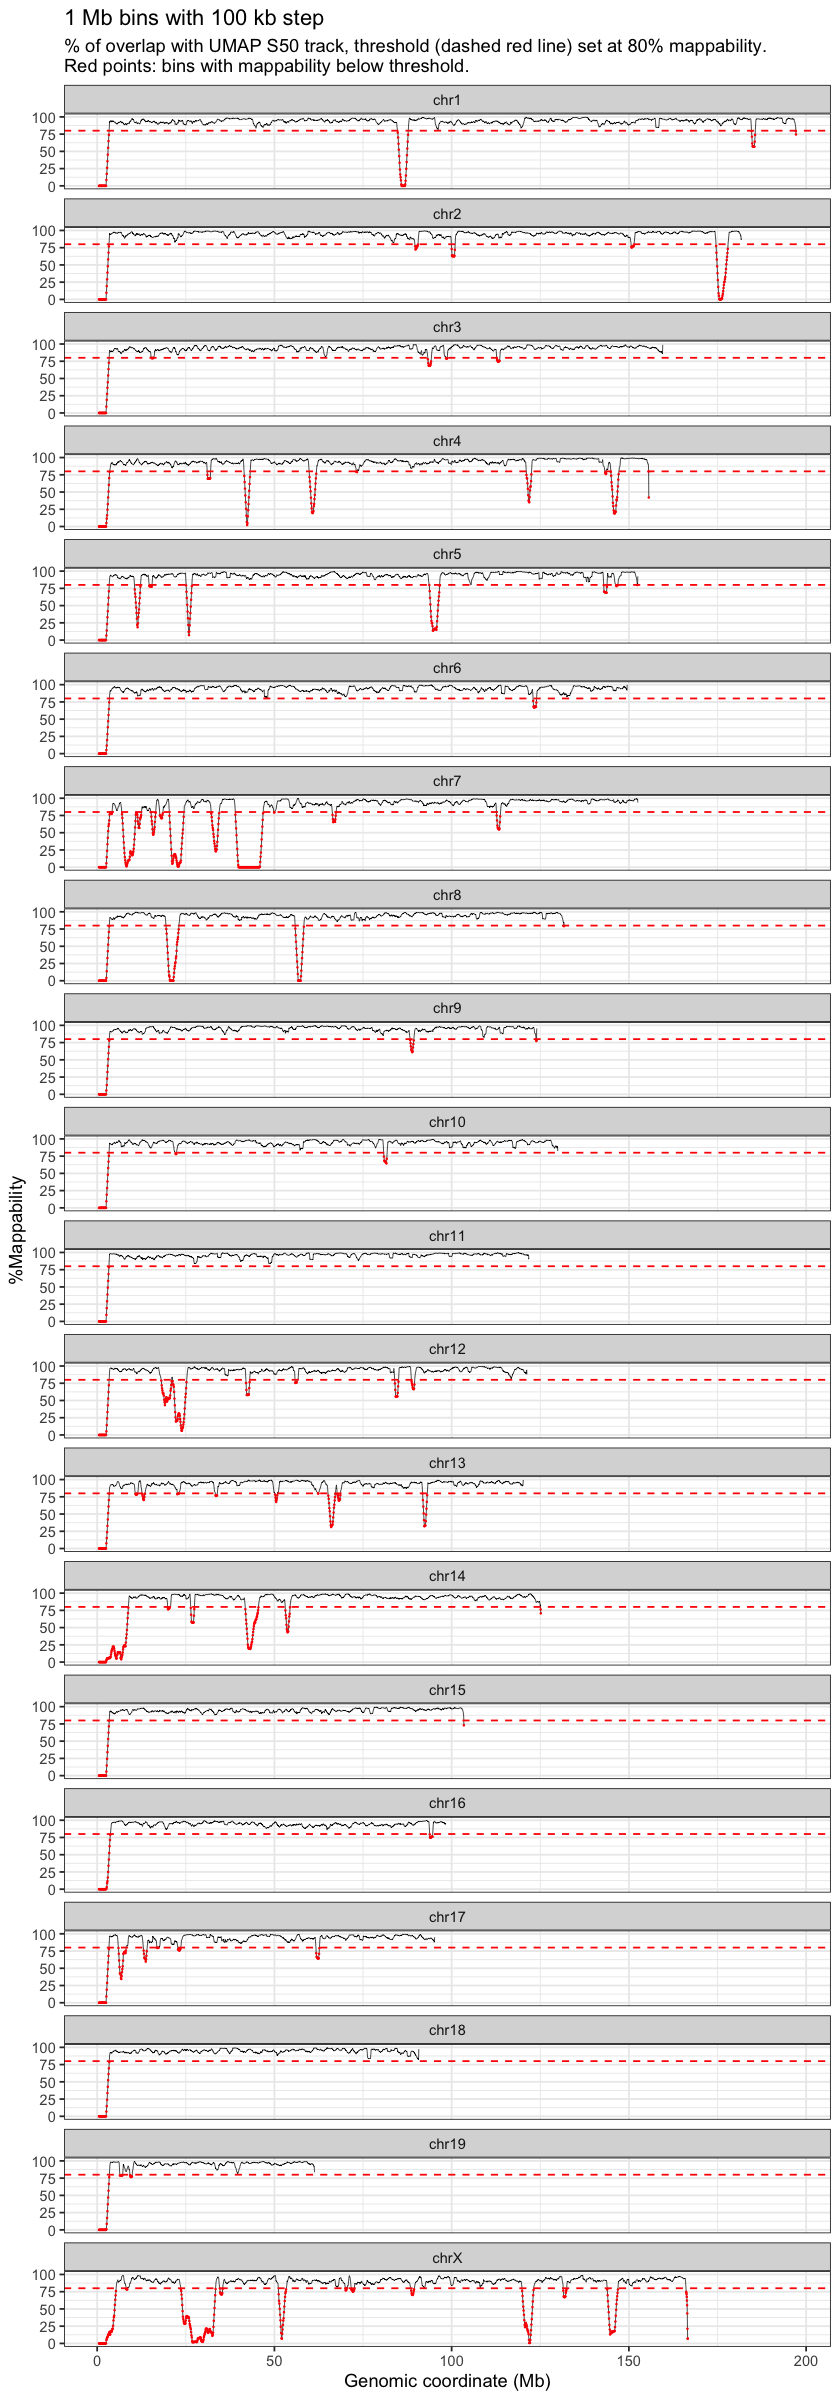

In [382]:
options(repr.plot.width=7, repr.plot.height=20)

threshold<-0.8
klen<-50

p = ggplot(bd_1m, aes((start + end) / 2e6, mappability * 100)
        ) + geom_line(size = .2
        ) + geom_point(data = bd_1m[mappability < threshold],
            color = "red", size = .05
        ) + facet_wrap(~chrom, ncol = 1
        ) + labs(x = "Genomic coordinate (Mb)", y = "%Mappability",
            title = "1 Mb bins with 100 kb step",
            subtitle = paste0(
                sprintf("%% of overlap with UMAP S%d track, ", klen),
                sprintf(
                    "threshold (dashed red line) set at %d%% mappability.\n",
                    threshold * 100),
                "Red points: bins with mappability below threshold.")
        ) + scale_color_manual(values = c("black", "red")
        ) + geom_hline(yintercept = threshold * 100,
            color = "red", linetype = "dashed"
        ) + theme_bw(
        )
p

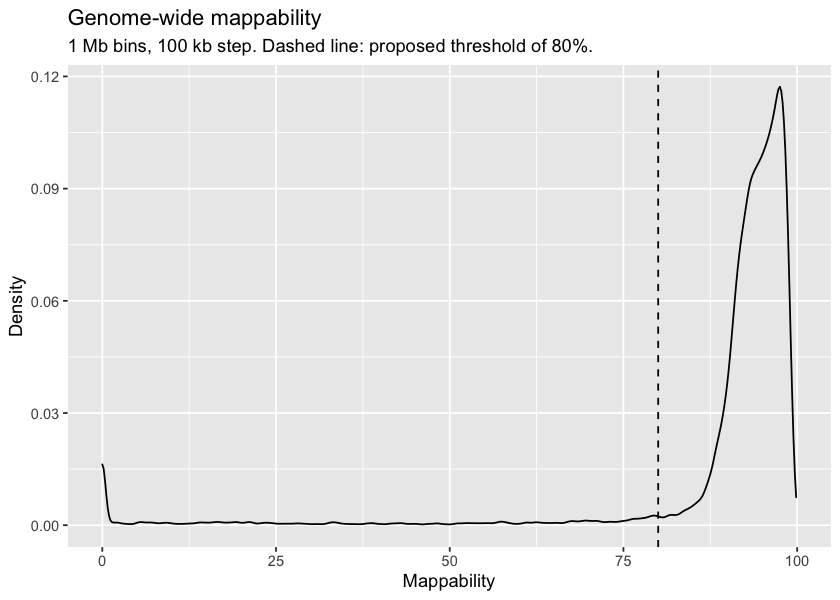

In [383]:
options(repr.plot.width=7, repr.plot.height=5)
p = ggplot(bd_1m, aes(mappability * 100)
        ) + geom_density(
        ) + geom_vline(xintercept = threshold * 100, linetype = "dashed"
        ) + labs(x = "Mappability", y = "Density",
            title = "Genome-wide mappability",
            subtitle = paste0("1 Mb bins, 100 kb step. ",
                sprintf("Dashed line: proposed threshold of %d%%.",
                    threshold * 100))
        )
p

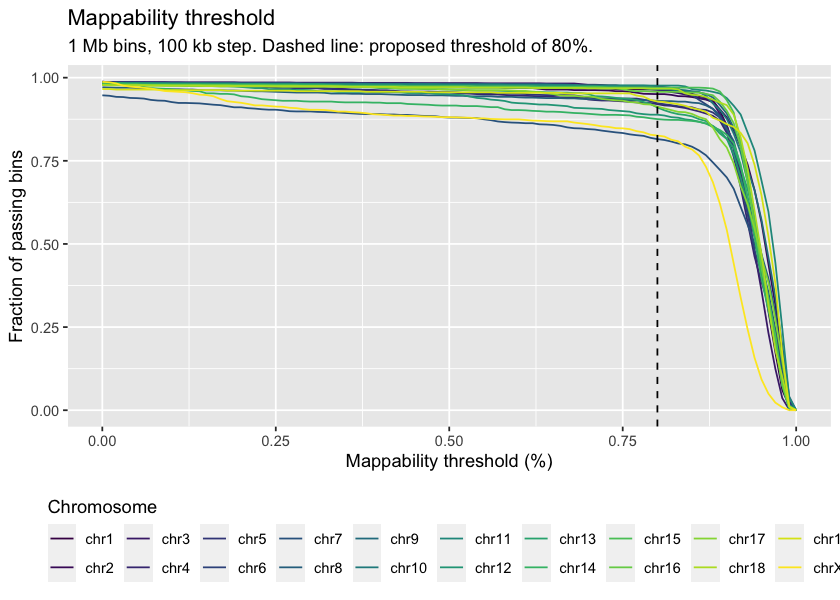

In [384]:
passing = rbindlist(lapply(seq(0, 1, by = .01), function(thr) {
        bd_1m[, list(pass = sum(get("mappability") > thr), N = .N, thr),
              by = chrom]
    }))
passing[, c("f") := list(get("pass") / get("N"))]
p = ggplot(passing, aes(x = thr, y = f, color = chrom)
        ) + geom_line(
        ) + geom_vline(xintercept = threshold, linetype = "dashed"
        ) + labs(x = "Mappability threshold (%)",
            y = "Fraction of passing bins",
            color = "Chromosome", title = "Mappability threshold",
            subtitle = paste0("1 Mb bins, 100 kb step. ",
                sprintf("Dashed line: proposed threshold of %d%%.",
                    threshold * 100))
        ) + theme(legend.position = "bottom"
        ) + guides(color = guide_legend(nrow = 2, title.position = "top")
        ) + scale_color_viridis(discrete = T)
p

Warning message:
“`guides(<scale> = FALSE)` is deprecated. Please use `guides(<scale> = "none")` instead.”


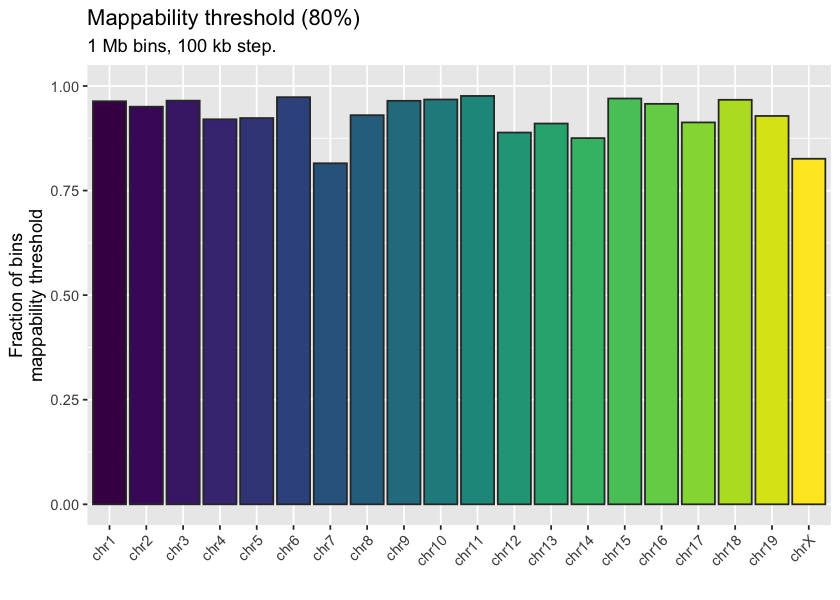

In [385]:
p = ggplot(passing[thr == threshold], aes(x = chrom, y = f, fill = chrom)
        ) + geom_col(color = "#323232"
        ) + scale_fill_viridis(discrete = T
        ) + guides(fill = F
        ) + theme(axis.text.x = element_text(angle = 45, hjust = 1)
        ) + coord_cartesian(ylim = c(0, 1)
        ) + labs(x = "", y = "Fraction of bins\nmappability threshold",
            title = sprintf("Mappability threshold (%d%%)", threshold * 100),
            subtitle = "1 Mb bins, 100 kb step."
        )
p

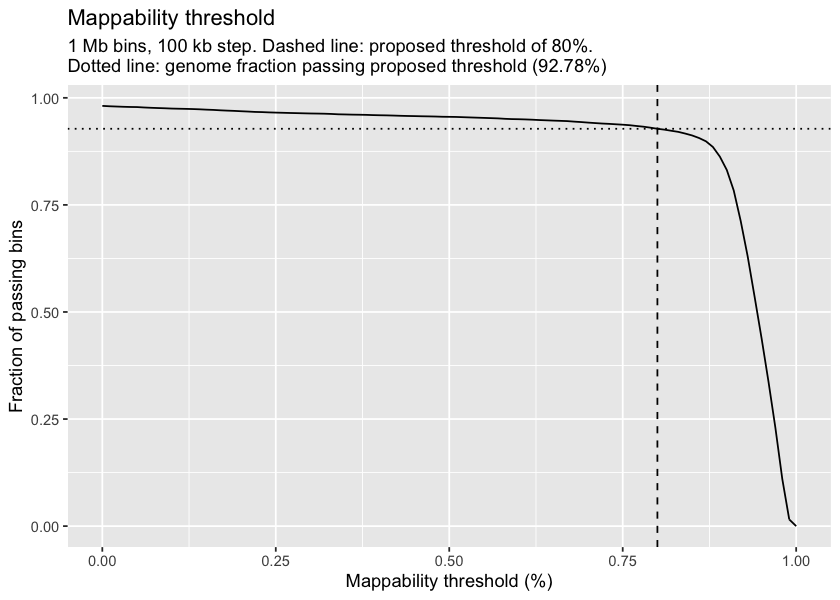

In [386]:
passing = rbindlist(lapply(seq(0, 1, by = .01), function(thr) {
        bd_1m[, list(pass = sum(get("mappability") > thr), N = .N, thr)]
    }))
passing[, c("f") := list(get("pass") / get("N"))]
passing_fraction = 1 - bd_1m[, sum(get("mappability") < threshold) / .N]
p = ggplot(passing, aes(x = thr, y = f)
        ) + geom_line(
        ) + geom_vline(xintercept = threshold, linetype = "dashed"
        ) + geom_hline(yintercept = passing_fraction,
            linetype = "dotted"
        ) + labs(x = "Mappability threshold (%)",
            y = "Fraction of passing bins",
            title = "Mappability threshold",
            subtitle = paste0("1 Mb bins, 100 kb step. ",
                sprintf("Dashed line: proposed threshold of %d%%.\n",
                    threshold * 100),
                "Dotted line: genome fraction passing proposed threshold ",
                sprintf("(%.2f%%)", passing_fraction * 100))
        ) + theme(legend.position = "bottom"
        )
p

In [387]:
write.table(bd_1m[mappability < threshold, .(chrom, start, end)], "mm9_low_mappability.UMAP_S50.bins_1e+06_1e+05.tsv",sep="\t",
            quote = F, row.names = FALSE, col.names = FALSE)